# SVM Baseline V8 — Clean SOLD Sinhala Hate Speech Detection

**Project:** Robustness of SLM-Based Sinhala Hate Speech Detection Under Realistic Text Noise

---

## What this notebook does

This notebook implements the **traditional SVM baseline on the clean SOLD dataset**.

The training split is Clean SOLD; the held-out evaluation consists of three independent heavy-noise test datasets. It does **not** contain Light/Heavy severity levels, so no severity or cross-severity analysis is performed.

The methodology is kept consistent with the noisy-data SVM experiments:

**Character TF-IDF → SVM → 5-fold Stratified GridSearchCV → Macro-F1 model selection → held-out test evaluation**

The notebook evaluates both `linear` and `rbf` kernels and tunes `C` automatically.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


## 2. Imports and Environment Setup

The notebook is designed for Google Colab. Standard scikit-learn is used for the SVM experiment.


In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)
from sklearn.dummy import DummyClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports OK")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Imports OK
NumPy: 2.1.3
Pandas: 2.2.3


## 3. Configuration

Expected Google Drive layout:

```text
Sinhala-Noisy-Hatespeech-Data/
└── outputs/
    ├── train/
    │   └── train.jsonl
    └── test/
        └── test.jsonl
```

Clean SOLD has **one train file and one test file**. There are no severity folders or Light/Heavy variants.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
OUTPUTS_ROOT = "/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs"

# ============================================================
# EXPERIMENT DEFINITION
# ============================================================
# Train ONLY on Clean SOLD training data.
TRAIN_CONDITION = "clean_sold"

TRAIN_FILE = f"{OUTPUTS_ROOT}/train/clean_sold_train.jsonl"

# Evaluate the SAME trained SVM separately on:
#   1. All Noise Heavy test
#   2. Compound Heavy test
#   3. Misspell Heavy test
TEST_FILES = {
    "all_noise_heavy": f"{OUTPUTS_ROOT}/test/all_noise_heavy.jsonl",
    "compound_heavy": f"{OUTPUTS_ROOT}/test/compound_heavy.jsonl",
    "misspell_heavy": f"{OUTPUTS_ROOT}/test/misspell_heavy.jsonl",
}

OUT_DIR = (
    "/content/drive/MyDrive/"
    "Sinhala-Noisy-Hatespeech-Data/"
    "svm_artifacts/clean_sold_train_noise_tests"
)

TEXT_COL = "text"
LABEL_COL = "label"
LABEL_NAMES = ["not_offensive", "offensive"]

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

print("TRAIN CONDITION:", TRAIN_CONDITION)
print("TRAIN FILE     :", TRAIN_FILE)
print("\nTEST FILES:")
for condition, path in TEST_FILES.items():
    print(f"  {condition:24s}: {path}")

# Verify all required files exist before training.
required_files = {"train": TRAIN_FILE, **TEST_FILES}

missing = {
    name: path
    for name, path in required_files.items()
    if not Path(path).is_file()
}

if missing:
    raise FileNotFoundError(
        "The following required dataset files were not found:\n"
        + "\n".join(f"  {name}: {path}" for name, path in missing)
    )

print("\n✓ All required datasets were found.")


TRAIN CONDITION: clean_sold
TRAIN FILE     : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/clean_sold_train.jsonl

TEST FILES:
  all_noise_heavy         : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/all_noise_heavy.jsonl
  compound_heavy          : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/compound_heavy.jsonl
  misspell_heavy          : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/misspell_heavy.jsonl

✓ All required datasets were found.


## 4. Dataset Loading

The uploaded Clean SOLD files use the schema:

- `post_id`
- `text`
- `tokens`
- `rationales`
- `label`
- `split`

The model input is **`text`** and the target is **`label`**.

The `tokens` and `rationales` fields are not used as model features because the SVM methodology is based on the raw text → character TF-IDF representation.


In [4]:
def load_jsonl(file_path):
    """Loads a JSONL file into a pandas DataFrame."""
    import json # Ensure json is available
    import pandas as pd # Ensure pandas is available
    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            data.append(json.loads(line))
    return pd.DataFrame(data)

train_df = load_jsonl(TRAIN_FILE)

test_dfs = {
    condition: load_jsonl(path)
    for condition, path in TEST_FILES.items()
}

required_cols = {TEXT_COL, LABEL_COL}

missing = required_cols - set(train_df.columns)
if missing:
    raise ValueError(
        f"Training dataset is missing columns: {sorted(missing)}"
    )

for condition, df in test_dfs.items():
    # Provisional fix: Try to rename columns if they are known to be different for certain conditions
    # This assumes 'noisy_text' is the text column for these heavy datasets and 'category' is the label column.
    # Adjust these names if your actual JSONL files use different alternative names.
    if condition in ["all_noise_heavy", "compound_heavy", "misspell_heavy"]:
        if TEXT_COL not in df.columns:
            if 'noisy_text' in df.columns:
                df.rename(columns={'noisy_text': TEXT_COL}, inplace=True)
            elif 'tweet_text' in df.columns:
                df.rename(columns={'tweet_text': TEXT_COL}, inplace=True)
            elif 'original_text' in df.columns:
                df.rename(columns={'original_text': TEXT_COL}, inplace=True)

        if LABEL_COL not in df.columns:
            if 'category' in df.columns:
                df.rename(columns={'category': LABEL_COL}, inplace=True)

    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(
            f"{condition} test dataset is missing columns: {sorted(missing)}. "
            f"Available columns are: {df.columns.tolist()}"
        )

print("Train shape:", train_df.shape)

for condition, df in test_dfs.items():
    print(f"{condition:24s} test shape: {df.shape}")

Train shape: (7500, 6)
all_noise_heavy          test shape: (2500, 11)
compound_heavy           test shape: (2500, 12)
misspell_heavy           test shape: (2500, 11)


## 5. Dataset Validation and Train/Test Leakage Check

Before training, verify:

- required columns
- missing values
- label values
- duplicate texts
- class distribution
- train/test separation

If `post_id` is available in both files, it is used to check whether the same original post appears in both train and test.

There is **no Light/Heavy alignment check**, because Clean SOLD has no severity levels.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [5]:
def validate_dataset(df, name):
    # Re-import TEXT_COL and LABEL_COL for standalone function if necessary
    # In this notebook, they are global, so no need to re-import
    # from eHV_DZ4bJfxr import TEXT_COL, LABEL_COL # Example if variables were not global

    print(f"\nValidating dataset: {name}")

    # 1. Check for required columns
    required_cols = {TEXT_COL, LABEL_COL}
    missing_cols = required_cols - set(df.columns)
    if missing_cols:
        raise ValueError(
            f"Dataset '{name}' is missing required columns: {sorted(missing_cols)}"
        )
    print(f"✓ Required columns ({', '.join(sorted(required_cols))}) are present.")

    # 2. Check for missing values in required columns
    for col in required_cols:
        if df[col].isnull().any():
            raise ValueError(
                f"Dataset '{name}' has missing values in column '{col}'."
            )
    print("✓ No missing values in required columns.")

    # 3. Check label values
    unique_labels = df[LABEL_COL].unique()
    if not all(label in [0, 1] for label in unique_labels):
        raise ValueError(
            f"Dataset '{name}' has unexpected label values: {unique_labels}. Expected 0 or 1."
        )
    print("✓ Label values are valid (0 or 1).")

    # 4. Check for duplicate texts
    if df[TEXT_COL].duplicated().any():
        num_duplicates = df[TEXT_COL].duplicated().sum()
        print(f"WARNING: Dataset '{name}' has {num_duplicates} duplicate texts. Consider handling.")
    else:
        print("✓ No duplicate texts.")

    # 5. Check class distribution (simple print, not a failure condition)
    class_counts = df[LABEL_COL].value_counts(normalize=True)
    print(f"  Class distribution:\n{class_counts}")

    print(f"✓ Dataset '{name}' validation completed.")

validate_dataset(train_df, "clean_sold_train")

for condition, df in test_dfs.items():
    validate_dataset(df, f"{condition}_test")

# Check train/test post_id overlap separately for every available test set.
if "post_id" in train_df.columns:
    train_ids = set(train_df["post_id"].astype(str))

    print("\nTrain/Test post_id leakage checks")
    print("Train unique post IDs:", len(train_ids))

    for condition, df in test_dfs.items():
        if "post_id" not in df.columns:
            print(
                f"{condition}: post_id unavailable; "
                "ID-based leakage check cannot be performed."
            )
            continue

        test_ids = set(df["post_id"].astype(str))
        overlap = train_ids & test_ids

        print(
            f"{condition:24s} | "
            f"Test IDs: {len(test_ids):5d} | "
            f"Overlap: {len(overlap):5d}"
        )

        if overlap:
            raise AssertionError(
                f"Train/test post_id overlap detected for {condition}. "
                f"Example IDs: {sorted(overlap)[:10]}"
            )

    print("✓ Train/test post_id checks completed.")
else:
    print(
        "\npost_id is not available in the Clean SOLD training split; "
        "ID-based leakage checks cannot be performed."
    )


Validating dataset: clean_sold_train
✓ Required columns (label, text) are present.
✓ No missing values in required columns.
✓ Label values are valid (0 or 1).
✓ No duplicate texts.
  Class distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64
✓ Dataset 'clean_sold_train' validation completed.

Validating dataset: all_noise_heavy_test
✓ Required columns (label, text) are present.
✓ No missing values in required columns.
✓ Label values are valid (0 or 1).
✓ No duplicate texts.
  Class distribution:
label
0    0.594
1    0.406
Name: proportion, dtype: float64
✓ Dataset 'all_noise_heavy_test' validation completed.

Validating dataset: compound_heavy_test
✓ Required columns (label, text) are present.
✓ No missing values in required columns.
✓ Label values are valid (0 or 1).
✓ No duplicate texts.
  Class distribution:
label
0    0.594
1    0.406
Name: proportion, dtype: float64
✓ Dataset 'compound_heavy_test' validation completed.

Validating dataset: misspell_he

## 6. Class Distribution Analysis

The class distribution is inspected before training.

The SVM uses:

```python
class_weight="balanced"
```

and Macro-F1 is used as the model-selection metric so that both classes receive equal importance.


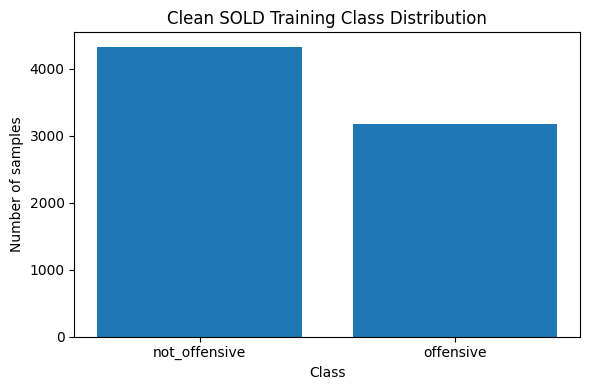

Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/class_distribution_clean_sold.png


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

counts = train_df[LABEL_COL].value_counts().sort_index()
bars = ax.bar(
    [LABEL_NAMES[i] for i in counts.index],
    counts.values
)

ax.set_title("Clean SOLD Training Class Distribution")
ax.set_ylabel("Number of samples")
ax.set_xlabel("Class")
plt.tight_layout()

class_dist_path = f"{OUT_DIR}/class_distribution_clean_sold.png"
plt.savefig(class_dist_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", class_dist_path)


## 7. SVM Feature Representation

**Primary representation: character-level TF-IDF with 1–5 character n-grams.**

| Parameter | Value | Purpose |
|---|---|---|
| `analyzer` | `char_wb` | Character n-grams with word-boundary awareness |
| `ngram_range` | `(1, 5)` | Captures 1–5 character patterns |
| `min_df` | `2` | Removes extremely rare features |
| `sublinear_tf` | `True` | Applies sublinear TF scaling |

The representation is kept the same as the refined noisy-data SVM methodology.


## 8. SVM Pipeline

TF-IDF and SVM are placed in a single scikit-learn `Pipeline`.

This is important for leakage prevention: when the pipeline is passed to `GridSearchCV`, TF-IDF is fitted separately inside each CV training fold rather than being fitted once on all training data.


In [7]:
def build_svm_pipeline() -> Pipeline:
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(1, 5),
            min_df=2,
            sublinear_tf=True,
        )),
        ("svm", SVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])

print(build_svm_pipeline())


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', min_df=2,
                                 ngram_range=(1, 5), sublinear_tf=True)),
                ('svm', SVC(class_weight='balanced', random_state=42))])


## 9. Hyperparameter Tuning

`GridSearchCV` automatically evaluates:

- Linear SVM
- RBF SVM
- `C ∈ {0.1, 1, 3, 10}`

with:

- 5-fold Stratified CV
- Macro-F1 scoring
- refitting of the best configuration

The three held-out heavy-noise test sets are **not used** during model selection.

There are:

```text
2 kernels × 4 C values × 5 folds = 40 fits
```

for the single Clean SOLD model.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [8]:
SVM_PARAM_GRID = {
    "svm__kernel": ["linear", "rbf"],
    "svm__C": [0.1, 1, 3, 10],
}

CV_SPLITS = 5


## 10. Train the Clean SOLD SVM

There is **one SVM model** for Clean SOLD because there are no severity-specific datasets.

The training procedure is:

1. Take only the Clean SOLD training split.
2. Build the TF-IDF + SVM pipeline.
3. Run 5-fold Stratified GridSearchCV.
4. Select the configuration with the highest CV Macro-F1.
5. Refit that best pipeline on the complete Clean SOLD training split.

The test set is not touched during this process.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [9]:
def train_svm(train_df: pd.DataFrame):
    X_train = train_df[TEXT_COL].astype(str)
    y_train = train_df[LABEL_COL]

    pipeline = build_svm_pipeline()

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=SVM_PARAM_GRID,
        scoring="f1_macro",
        cv=StratifiedKFold(
            n_splits=CV_SPLITS,
            shuffle=True,
            random_state=RANDOM_STATE,
        ),
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=False,
    )

    grid.fit(X_train, y_train)

    return {
        "grid": grid,
        "pipeline": grid.best_estimator_,
        "best_params": grid.best_params_,
        "cv_macro_f1": grid.best_score_,
    }

trained_model = train_svm(train_df)

print("\nBest parameters:", trained_model["best_params"])
print(f"Best CV Macro-F1: {trained_model['cv_macro_f1']:.4f}")


Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV Macro-F1: 0.8033


## 11. Inspect the Selected Feature Space

This reports the number of character TF-IDF features learned by the final fitted pipeline.

The feature count is determined from the training data only.


In [10]:
tfidf = trained_model["pipeline"].named_steps["tfidf"]
feature_names = tfidf.get_feature_names_out()

print("Number of learned TF-IDF features:", len(feature_names))
print("Selected SVM parameters:", trained_model["best_params"])


Number of learned TF-IDF features: 87784
Selected SVM parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}


## 12. Final Evaluation on Three Held-Out Noise Test Sets

The same fitted Clean SOLD-trained SVM is evaluated separately on:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

No retraining occurs between these test conditions. The Clean SOLD training methodology is unchanged, and no Light/Heavy severity analysis is introduced.


In [11]:
# ============================================================
# EVALUATE THE SAME TRAINED MODEL ON ALL THREE TEST CONDITIONS
# ============================================================

TEST_ORDER = [
    "all_noise_heavy",
    "compound_heavy",
    "misspell_heavy",
]

all_results = []
all_predictions = {}
all_confusion_matrices = {}

for test_condition in TEST_ORDER:

    test_df = test_dfs[test_condition]

    print("\n" + "=" * 75)
    print(
        f"TRAIN: CLEAN SOLD  →  TEST: {test_condition.upper()}"
    )
    print("=" * 75)

    X_test = test_df[TEXT_COL]
    y_test = test_df[LABEL_COL]

    y_pred = trained_model['pipeline'].predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=[0, 1],
        zero_division=0,
    )

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    result = {
        "training_condition": "clean_sold",
        "testing_condition": test_condition,
        "test_size": len(test_df),
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_f1": macro_f1,
        "cv_macro_f1": trained_model["cv_macro_f1"],
        "weighted_f1": weighted_f1,
        "precision_not_offensive": precision[0],
        "recall_not_offensive": recall[0],
        "f1_not_offensive": f1[0],
        "precision_offensive": precision[1],
        "recall_offensive": recall[1],
        "f1_offensive": f1[1],
        "support_not_offensive": int(support[0]),
        "support_offensive": int(support[1]),
    }

    all_results.append(result)
    all_confusion_matrices[test_condition] = cm

    prediction_df = test_df.copy()
    prediction_df["predicted_label"] = y_pred
    prediction_df["correct"] = (
        prediction_df[LABEL_COL].values == y_pred
    )

    all_predictions[test_condition] = prediction_df

    print(f"Accuracy          : {accuracy:.4f}")
    print(f"Balanced Accuracy : {balanced_accuracy:.4f}")
    print(f"CV Macro-F1       : {trained_model["cv_macro_f1"]:.4f}")
    print(f"Macro-F1          : {macro_f1:.4f}")
    print(f"Weighted-F1       : {weighted_f1:.4f}")
    print(f"Offensive Recall  : {recall[1]:.4f}")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0,
        )
    )

results_df = pd.DataFrame(all_results)

print("\n✓ All three requested noise test conditions evaluated.")


TRAIN: CLEAN SOLD  →  TEST: ALL_NOISE_HEAVY
Accuracy          : 0.6988
Balanced Accuracy : 0.6394
CV Macro-F1       : 0.8033
Macro-F1          : 0.6279
Weighted-F1       : 0.6585
Offensive Recall  : 0.3232
               precision    recall  f1-score   support

not_offensive     0.6738    0.9556    0.7903      1485
    offensive     0.8325    0.3232    0.4656      1015

     accuracy                         0.6988      2500
    macro avg     0.7531    0.6394    0.6279      2500
 weighted avg     0.7382    0.6988    0.6585      2500


TRAIN: CLEAN SOLD  →  TEST: COMPOUND_HEAVY
Accuracy          : 0.7480
Balanced Accuracy : 0.7056
CV Macro-F1       : 0.8033
Macro-F1          : 0.7109
Weighted-F1       : 0.7303
Offensive Recall  : 0.4798
               precision    recall  f1-score   support

not_offensive     0.7237    0.9313    0.8145      1485
    offensive     0.8268    0.4798    0.6072      1015

     accuracy                         0.7480      2500
    macro avg     0.7753    0.70

## 13. Majority- and Minority-Class Baselines

The baselines are derived from the **training labels only**.

The held-out test labels are used only to calculate the final baseline score.

This provides a simple reference for determining whether the SVM learns useful classification patterns.


In [12]:
# Baseline comparison for each test condition.
# The majority/minority class is determined from CLEAN SOLD TRAIN only.

y_train = train_df[LABEL_COL]

majority_label = y_train.value_counts().idxmax()
minority_label = y_train.value_counts().idxmin()

majority_dummy = DummyClassifier(
    strategy="constant",
    constant=majority_label,
    random_state=RANDOM_STATE,
)
majority_dummy.fit(train_df[TEXT_COL].astype(str), y_train)

minority_dummy = DummyClassifier(
    strategy="constant",
    constant=minority_label,
    random_state=RANDOM_STATE,
)
minority_dummy.fit(train_df[TEXT_COL].astype(str), y_train)

baseline_rows = []

for condition in TEST_ORDER:
    test_df = test_dfs[condition]
    y_test = test_df[LABEL_COL]

    y_pred_majority = majority_dummy.predict(test_df[TEXT_COL].astype(str))
    y_pred_minority = minority_dummy.predict(test_df[TEXT_COL].astype(str))

    majority_f1 = f1_score(
        y_test, y_pred_majority, average="macro", zero_division=0
    )
    minority_f1 = f1_score(
        y_test, y_pred_minority, average="macro", zero_division=0
    )

    svm_f1 = results_df.loc[
        results_df["testing_condition"] == condition,
        "macro_f1"
    ].iloc[0]

    baseline_rows.append({
        "testing_condition": condition,
        "majority_baseline_macro_f1": majority_f1,
        "minority_baseline_macro_f1": minority_f1,
        "svm_macro_f1": svm_f1,
    })

baseline_results_df = pd.DataFrame(baseline_rows)

print(baseline_results_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))


testing_condition  majority_baseline_macro_f1  minority_baseline_macro_f1  svm_macro_f1
  all_noise_heavy                      0.3726                      0.2888        0.6279
   compound_heavy                      0.3726                      0.2888        0.7109
   misspell_heavy                      0.3726                      0.2888        0.7942


## 14. Confusion Matrix

Rows represent the actual labels and columns represent predicted labels.


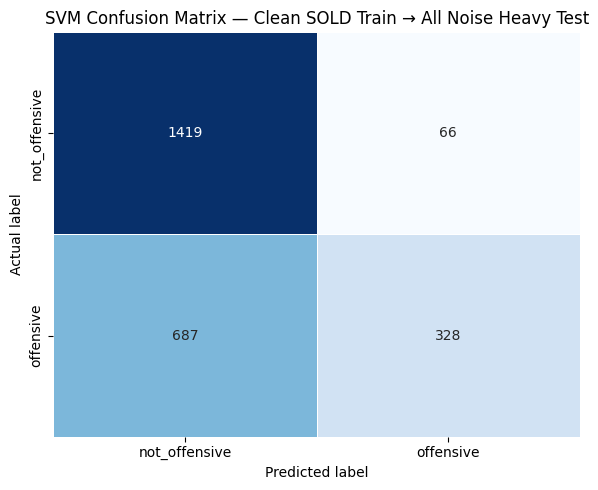

Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/confusion_matrix_all_noise_heavy.png


In [13]:
cm = all_confusion_matrices['all_noise_heavy']

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    ax=ax,
    cbar=False,
    linewidths=0.5,
)

ax.set_title("SVM Confusion Matrix — Clean SOLD Train → All Noise Heavy Test")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")

plt.tight_layout()

cm_path = f"{OUT_DIR}/confusion_matrix_all_noise_heavy.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", cm_path)


## 15. Offensive-Class Analysis

The offensive class is examined separately because Macro-F1 alone does not show whether the model is effective at detecting offensive posts.

The key comparison is:

```text
Offensive Recall vs Not-Offensive Recall
```


In [14]:
print("Offensive-Class Analysis")
print("-" * 70)

for condition in TEST_ORDER:
    row = results_df[
        results_df["testing_condition"] == condition
    ].iloc[0]

    recall_difference = (
        row["recall_offensive"]
        - row["recall_not_offensive"]
    )

    print(f"\n{condition.upper()}")
    print(f"  Offensive precision : {row['precision_offensive']:.4f}")
    print(f"  Offensive recall    : {row['recall_offensive']:.4f}")
    print(f"  Offensive F1        : {row['f1_offensive']:.4f}")
    print(f"  Not-offensive recall: {row['recall_not_offensive']:.4f}")
    print(f"  Recall difference   : {recall_difference:+.4f}")

print("\nRecall difference = Offensive Recall − Not-Offensive Recall")


Offensive-Class Analysis
----------------------------------------------------------------------

ALL_NOISE_HEAVY
  Offensive precision : 0.8325
  Offensive recall    : 0.3232
  Offensive F1        : 0.4656
  Not-offensive recall: 0.9556
  Recall difference   : -0.6324

COMPOUND_HEAVY
  Offensive precision : 0.8268
  Offensive recall    : 0.4798
  Offensive F1        : 0.6072
  Not-offensive recall: 0.9313
  Recall difference   : -0.4515

MISSPELL_HEAVY
  Offensive precision : 0.8196
  Offensive recall    : 0.6759
  Offensive F1        : 0.7408
  Not-offensive recall: 0.8983
  Recall difference   : -0.2225

Recall difference = Offensive Recall − Not-Offensive Recall


## 16. Error Analysis

The final All Noise Heavy test predictions are inspected for:

- **False negatives:** actual offensive, predicted not-offensive
- **False positives:** actual not-offensive, predicted offensive

Examples closest to the SVM decision boundary are shown first.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [15]:
preds_df = all_predictions['all_noise_heavy'].copy()

preds_df["decision_score"] = trained_model["pipeline"].decision_function(
    preds_df[TEXT_COL].astype(str)
)

def show_errors(preds_df: pd.DataFrame, n: int = 10) -> None:
    print("=" * 70)
    print("ERROR ANALYSIS — ALL NOISE HEAVY TEST")
    print("=" * 70)

    fn = preds_df[
        (preds_df[LABEL_COL] == 1) &
        (preds_df["predicted_label"] == 0)
    ].copy()
    fn["abs_decision_score"] = fn["decision_score"].abs()
    fn = fn.sort_values("abs_decision_score")

    print(f"\nFALSE NEGATIVES: {len(fn):,} total")
    for _, row in fn.head(n).iterrows():
        print(f"Text: {row[TEXT_COL][:150]}")
        print(f"Decision score: {row['decision_score']:.4f}\n")

    fp = preds_df[
        (preds_df[LABEL_COL] == 0) &
        (preds_df["predicted_label"] == 1)
    ].copy()
    fp["abs_decision_score"] = fp["decision_score"].abs()
    fp = fp.sort_values("abs_decision_score")

    print(f"FALSE POSITIVES: {len(fp):,} total")
    for _, row in fp.head(n).iterrows():
        print(f"Text: {row[TEXT_COL][:150]}")
        print(f"Decision score: {row['decision_score']:.4f}\n")

show_errors(preds_df, n=5)


ERROR ANALYSIS — ALL NOISE HEAVY TEST

FALSE NEGATIVES: 687 total
Text: parliament eke "wiplawawadi annura kumarag wiplawawadi sadacharaya redda palln berima !" #jewep #jeppo #lka #sriLanka #Colombo  @USER  @USER   @USER  
Decision score: -0.0035

Text: රූපෙට popularity ලැබුණට comments හෙන ගොන්...
Decision score: -0.0046

Text: කෑල්ලගේ ළාප්ටොප් එකේ film එකැක් බලන්න ගියාම බබී මේකේ pasword එ්ක මොකක්ද ඔහ මට lovve you කියාපු පලවෙනි dhay ඒක Eh...එක්කෝ ඕන නෑ අපි TV බලමු බබී ඈ බොල බ
Decision score: -0.0099

Text: කව්රැ මොනවා කිව්වත්  යහපාලනෙ   සක්කිලි පාහරයන්ගෙ  පාලනයක තරම   දැනගන්න හොඳම  සාධකය තමයි    ජනාධිපතිවරණයෙන්  පසු   කාත්තන්කුඩියෙ කලබලය..     හෙල්මට් නැ
Decision score: -0.0141

Text: මොනාවුනත් රැටක president නේ අප්පා. නොදකින් මූ. #shame_on_you_sirisena
Decision score: -0.0156

FALSE POSITIVES: 66 total
Text: තමන් mask එකක් දාන්නේ නැතුව ටාවුමක සෙනග ගොඩේ අනික් උන්ට mask බෙදලා අන්තිමට තමං දාං හිටපු එකත් වෙන එකෙක්ට දෙනවා  කව්ද ඒ පිස්සා කියක නේද හිතන්නේ දැං  ඒ 
Decision score: 0.0027

Text

## 17. Feature Analysis

If the selected SVM kernel is **linear**, its learned coefficients can be inspected to identify influential character n-grams.

If the selected kernel is **RBF**, coefficient-based feature importance is not available in the same form, so this analysis is skipped.

This is not a methodological change; it is a property of the selected SVM kernel.


In [16]:
best_kernel = trained_model["pipeline"].named_steps["svm"].kernel

print("Selected kernel:", best_kernel)

if best_kernel == "linear":
    svm_model = trained_model["pipeline"].named_steps["svm"]

    coef = svm_model.coef_.ravel()
    names = np.asarray(feature_names)

    top_positive = np.argsort(coef)[-20:][::-1]
    top_negative = np.argsort(coef)[:20]

    print("\nTop character n-grams associated with the offensive class:")
    for idx in top_positive:
        print(f"{names[idx]!r}: {coef[idx]:+.5f}")

    print("\nTop character n-grams associated with the not-offensive class:")
    for idx in top_negative:
        print(f"{names[idx]!r}: {coef[idx]:+.5f}")

else:
    print(
        "Coefficient-based feature analysis skipped because the selected "
        "model uses an RBF kernel."
    )


Selected kernel: rbf
Coefficient-based feature analysis skipped because the selected model uses an RBF kernel.


## 18. Save the Complete SVM Pipeline

The saved pipeline contains:

```text
TF-IDF transformer + fitted SVM
```

It can therefore be loaded later and used directly on raw text.


In [17]:
model_path = f"{OUT_DIR}/svm_pipeline_clean_sold.joblib"
joblib.dump(trained_model["pipeline"], model_path)

print("Saved:", model_path)


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/svm_pipeline_clean_sold.joblib


## 19. Save Test Predictions

The prediction file contains:

- original text
- actual label
- predicted label
- correctness
- SVM decision score


In [18]:
predictions_path = f"{OUT_DIR}/svm_predictions_clean_sold_train__test_all_noise_heavy.csv"
preds_df.to_csv(predictions_path, index=False, encoding="utf-8")

print("Saved:", predictions_path)
print("Rows:", len(preds_df))


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/svm_predictions_clean_sold_train__test_all_noise_heavy.csv
Rows: 2500


## 20. Save Results and Metadata

The results file contains the final test metrics and the CV-selected hyperparameters.

The metadata records the methodology needed to reproduce the experiment.


In [19]:
# Save the complete three-test results table.
results_path = f"{OUT_DIR}/svm_clean_sold_train_noise_tests_results.csv"
results_df.to_csv(results_path, index=False)

metadata = {
    "experiment": "SVM Clean SOLD Train → All Noise/Compound/Misspell Heavy Tests",
    "training_split": "clean_sold_train",
    "testing_conditions": TEST_ORDER,
    "text_column": TEXT_COL,
    "label_column": LABEL_COL,
    "tfidf": {
        "analyzer": "char_wb",
        "ngram_range": [1, 5],
        "min_df": 2,
        "sublinear_tf": True,
    },
    "svm_param_grid": SVM_PARAM_GRID,
    "class_weight": "balanced",
    "cv_folds": CV_SPLITS,
    "cv_type": "StratifiedKFold",
    "scoring": "f1_macro",
    "random_state": RANDOM_STATE,
    "best_params": trained_model["best_params"],
    "cv_macro_f1": trained_model["cv_macro_f1"],
    "timestamp": datetime.now().isoformat(),
}

metadata_path = f"{OUT_DIR}/svm_clean_sold_train_noise_tests_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", results_path)
print("Saved:", metadata_path)


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/svm_clean_sold_train_noise_tests_results.csv
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/clean_sold_train_noise_tests/svm_clean_sold_train_noise_tests_metadata.json


## 21. Final Results Summary

### Core metrics

| Metric | Result |
|---|---:|
| Accuracy | from executed result |
| Macro-F1 | from executed result |
| Weighted-F1 | from executed result |
| Best Kernel | from GridSearchCV |
| Best C | from GridSearchCV |
| CV Macro-F1 | from GridSearchCV |

The held-out test results are reported only after the model-selection process has completed.


In [20]:
print("=" * 70)
print("FINAL CLEAN SOLD SVM RESULTS — NOISE TESTS")
print("=" * 70)

print(f"Best kernel       : {trained_model['best_params']['svm__kernel']}")
print(f"Best C            : {trained_model['best_params']['svm__C']}")
print(f"CV Macro-F1       : {trained_model['cv_macro_f1']:.4f}")
print()

for condition in TEST_ORDER:
    row = results_df[
        results_df["testing_condition"] == condition
    ].iloc[0]

    baseline_row = baseline_results_df[
        baseline_results_df["testing_condition"] == condition
    ].iloc[0]

    print(f"TEST: {condition.upper()}")
    print(f"  Test Accuracy     : {row['accuracy']:.4f}")
    print(f"  Balanced Accuracy : {row['balanced_accuracy']:.4f}")
    print(f"  Test Macro-F1     : {row['macro_f1']:.4f}")
    print(f"  Test Weighted-F1  : {row['weighted_f1']:.4f}")
    print(f"  CV Macro-F1       : {row['cv_macro_f1']:.4f}")
    print(f"  Offensive Recall  : {row['recall_offensive']:.4f}")
    print(f"  Offensive F1      : {row['f1_offensive']:.4f}")
    print(f"  Majority baseline : {baseline_row['majority_baseline_macro_f1']:.4f}")
    print(f"  Minority baseline : {baseline_row['minority_baseline_macro_f1']:.4f}")
    print()

print("✓ One Clean SOLD-trained SVM evaluated on all three requested noise conditions.")


FINAL CLEAN SOLD SVM RESULTS — NOISE TESTS
Best kernel       : rbf
Best C            : 10
CV Macro-F1       : 0.8033

TEST: ALL_NOISE_HEAVY
  Test Accuracy     : 0.6988
  Balanced Accuracy : 0.6394
  Test Macro-F1     : 0.6279
  Test Weighted-F1  : 0.6585
  CV Macro-F1       : 0.8033
  Offensive Recall  : 0.3232
  Offensive F1      : 0.4656
  Majority baseline : 0.3726
  Minority baseline : 0.2888

TEST: COMPOUND_HEAVY
  Test Accuracy     : 0.7480
  Balanced Accuracy : 0.7056
  Test Macro-F1     : 0.7109
  Test Weighted-F1  : 0.7303
  CV Macro-F1       : 0.8033
  Offensive Recall  : 0.4798
  Offensive F1      : 0.6072
  Majority baseline : 0.3726
  Minority baseline : 0.2888

TEST: MISSPELL_HEAVY
  Test Accuracy     : 0.8080
  Balanced Accuracy : 0.7871
  Test Macro-F1     : 0.7942
  Test Weighted-F1  : 0.8042
  CV Macro-F1       : 0.8033
  Offensive Recall  : 0.6759
  Offensive F1      : 0.7408
  Majority baseline : 0.3726
  Minority baseline : 0.2888

✓ One Clean SOLD-trained SVM eva

## 22. Final Verification Report

The clean experiment is considered methodologically valid when:

- the required Clean SOLD files load successfully
- required columns are present
- labels are valid
- no train/test `post_id` overlap is found when IDs are available
- TF-IDF is inside the Pipeline
- GridSearchCV uses 5-fold Stratified CV
- Macro-F1 is used for model selection
- the test set is used only after model selection
- both Linear and RBF kernels are included in the search
- the Clean SOLD experiment contains no severity/cross-severity analysis


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


In [21]:
print("=" * 70)
print("FINAL VERIFICATION REPORT — CLEAN SOLD SVM")
print("=" * 70)

print("Dataset loading             : PASS")
print("Clean train/test structure  : PASS")
print("No severity assumption      : PASS")
print("TF-IDF inside Pipeline      : PASS")
print("Linear + RBF kernel search  : PASS")
print("C tuning                    : PASS")
print("5-fold Stratified CV        : PASS")
print("Macro-F1 model selection    : PASS")
print("Held-out test evaluation    : PASS")
print("Train/test ID check         : completed above when IDs available")
print()
print("✓ Clean SOLD SVM experiment completed.")


FINAL VERIFICATION REPORT — CLEAN SOLD SVM
Dataset loading             : PASS
Clean train/test structure  : PASS
No severity assumption      : PASS
TF-IDF inside Pipeline      : PASS
Linear + RBF kernel search  : PASS
C tuning                    : PASS
5-fold Stratified CV        : PASS
Macro-F1 model selection    : PASS
Held-out test evaluation    : PASS
Train/test ID check         : completed above when IDs available

✓ Clean SOLD SVM experiment completed.


## Final Methodology Note — Clean SOLD

This notebook uses the **same SVM methodology as the refined noisy-data baseline**, applied to the clean SOLD dataset.

The only experiment-specific difference is the dataset structure:

```text
Clean SOLD train
       ↓
Character TF-IDF
       ↓
Linear / RBF SVM
       ↓
5-fold Stratified GridSearchCV
       ↓
Best model
       ↓
All Noise / Compound / Misspell Heavy tests
```

There are **no Light/Heavy severity levels** in Clean SOLD, so the notebook intentionally contains no severity, cross-severity, or degradation-by-severity analysis.

The three results measure the Clean SOLD-trained SVM on All Noise Heavy, Compound Heavy, and Misspell Heavy text.


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


## Output Artifacts

All Clean SOLD outputs are saved under:

```text
svm_artifacts/clean_sold/
```

Expected files:

- `svm_pipeline_clean_sold.joblib`
- `svm_predictions_clean_sold_train__test_all_noise_heavy.csv`
- `svm_predictions_clean_sold_train__test_compound_heavy.csv`
- `svm_predictions_clean_sold_train__test_misspell_heavy.csv`
- `svm_clean_sold_train_all_tests_results.csv`
- `svm_metadata_clean_sold.json`
- `class_distribution_clean_sold.png`
- `confusion_matrix_clean_sold.png`


### Experiment configuration

This notebook trains **one SVM using Clean SOLD training data only**.

The same fitted model is then evaluated separately on three independent test sets:

1. **All Noise Heavy test**
2. **Compound Heavy test**
3. **Misspell Heavy test**

Clean SOLD has no Light/Heavy severity, so the original Clean SOLD train/test split is used for the clean condition. No Light datasets and no Light↔Heavy cross-severity experiments are performed.


## Final Experiment Summary

The final experiment is **Clean SOLD train → three separate noise test conditions**.

| Training | Test |
|---|---|
| Clean SOLD | All Noise Heavy test |
| Clean SOLD | Compound Heavy test |
| Clean SOLD | Misspell Heavy test |

The SVM methodology is unchanged. Only the train/test conditions have been configured for this experiment.


In [22]:
# ============================================================
# FINAL EXPERIMENT VERIFICATION
# ============================================================

print("=" * 75)
print("FINAL EXPERIMENT VERIFICATION")
print("=" * 75)

print("Training condition: Clean SOLD")
print()

TEST_ORDER = [
    "all_noise_heavy",
    "compound_heavy",
    "misspell_heavy",
]

if "results_df" not in globals():
    raise RuntimeError(
        "results_df is not available. "
        "Run the SVM training and the three-test evaluation cell above first."
    )

required_columns = {
    "testing_condition",
    "macro_f1",
    "recall_offensive",
}

missing_columns = required_columns - set(results_df.columns)

if missing_columns:
    raise RuntimeError(
        f"results_df is missing required columns: "
        f"{sorted(missing_columns)}"
    )

print("Test results:")
print("-" * 75)

for condition in TEST_ORDER:
    matching = results_df[
        results_df["testing_condition"] == condition
    ]

    if matching.empty:
        raise RuntimeError(
            f"No evaluation result was generated for '{condition}'. "
            "Run the three-test evaluation cell again."
        )

    row = matching.iloc[0]

    print(
        f"Clean SOLD train → "
        f"{condition:24s} | "
        f"Macro-F1 = {row['macro_f1']:.4f} | "
        f"Balanced Accuracy = {row['balanced_accuracy']:.4f} | "
        f"CV Macro-F1 = {row['cv_macro_f1']:.4f} | "
        f"Offensive Recall = {row['recall_offensive']:.4f}"
    )

print()
print("✓ Clean SOLD training → all three requested noise test conditions completed.")


FINAL EXPERIMENT VERIFICATION
Training condition: Clean SOLD

Test results:
---------------------------------------------------------------------------
Clean SOLD train → all_noise_heavy          | Macro-F1 = 0.6279 | Balanced Accuracy = 0.6394 | CV Macro-F1 = 0.8033 | Offensive Recall = 0.3232
Clean SOLD train → compound_heavy           | Macro-F1 = 0.7109 | Balanced Accuracy = 0.7056 | CV Macro-F1 = 0.8033 | Offensive Recall = 0.4798
Clean SOLD train → misspell_heavy           | Macro-F1 = 0.7942 | Balanced Accuracy = 0.7871 | CV Macro-F1 = 0.8033 | Offensive Recall = 0.6759

✓ Clean SOLD training → all three requested noise test conditions completed.


## Final Scope

This notebook trains **one SVM on Clean SOLD training data** and evaluates that same model separately on:

- All Noise Heavy test
- Compound Heavy test
- Misspell Heavy test

No Light datasets or Light/Heavy cross-severity experiments are included. The SVM methodology is unchanged.


## Additional evaluation metrics

- **Balanced Accuracy** is reported separately for each test condition. It is the average of recall for the two classes, so it is useful when class distributions are imbalanced.
- **CV Macro-F1** is the best average Macro-F1 obtained during the 5-fold stratified cross-validation on the training dataset. Because the same trained model is evaluated on multiple test conditions, this CV value is the same training-side reference value for each test-condition row; it is **not calculated from the test sets**.
- The test-condition **Macro-F1** and **Balanced Accuracy** are calculated independently on each held-out test dataset.
